# M3 summary: every experiment in one place

This notebook collects the results of all the Milestone 3 training runs, which were separate executions of notebook 12 (E1 to E4, the N0 noise floor, the FE front ends, K1 and the H1 retrains) and notebook 14 (the H1 search), plus the baselines from notebook 11, the verdict-level results from notebook 19, and our final model against B1 on the species both know.

**Inputs:** each run's summary table (`results/m3/<stage>/summary_*.csv`), the decision summaries, the baseline comparisons and the H1 Optuna study. **Outputs:** four combined tables in `results/m3/summary/`, which the rest of the notebook reads. **Runs on:** any CPU, in a few seconds.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # optuna's progress bar wants ipywidgets

from pathlib import Path

import matplotlib.pyplot as plt
import optuna
import pandas as pd

RESULTS = Path("../results/m3")
SUMMARY = RESULTS / "summary"
pd.set_option("display.width", 160, "display.max_columns", 20, "display.precision", 3)


def stage(run):
    if run.startswith("H1_top"):
        return "retrain"
    if run.startswith(("R_F0", "FE_")):
        return "FE"
    return run.split("_")[0]

## 1. Combine the per-run tables

In [2]:
raw = sorted(RESULTS.glob("*/summary_*.csv"))
if raw:
    runs = pd.concat([pd.read_csv(f) for f in raw], ignore_index=True).drop_duplicates("run", keep="last")
    runs.insert(0, "stage", runs["run"].map(stage))
    decision_files = [RESULTS / "e1/decision_summary.csv", RESULTS / "e2/decision_summary.csv",
                      RESULTS / "fe/decision_summary.csv", RESULTS / "retrain/decision_summary_head.csv"]
    verdicts = pd.concat([pd.read_csv(f) for f in decision_files], ignore_index=True).drop_duplicates("run", keep="last")
    baselines = pd.concat([pd.read_csv(RESULTS / f"baselines_v{v}/comparison.csv") for v in (1, 2, 3)])
    baselines = baselines.drop_duplicates("model", keep="last")  # later runs re-ran the baselines that failed first
    study = optuna.load_study(study_name="H1", storage=f"sqlite:///{RESULTS / 'h1/H1_merged.db'}")
    trials = study.trials_dataframe()[["number", "value", "params_lr", "params_weight_decay", "params_arcface_m",
                                       "params_aug_strength", "state"]]
    SUMMARY.mkdir(exist_ok=True)
    for name, table in [("model_runs", runs), ("verdict_runs", verdicts), ("baselines", baselines), ("h1_trials", trials)]:
        table.to_csv(SUMMARY / f"{name}.csv", index=False)
    print(f"combined {len(raw)} run tables: {len(runs)} runs, {len(verdicts)} decision reports, "
          f"{len(baselines)} baselines, {len(trials)} H1 trials")
runs, verdicts, baselines, trials = (pd.read_csv(SUMMARY / f"{n}.csv")
                                     for n in ("model_runs", "verdict_runs", "baselines", "h1_trials"))

combined 16 run tables: 30 runs, 28 decision reports, 8 baselines, 24 H1 trials


## 2. Baselines (notebook 11): no training on our photos

In [3]:
baselines[["model", "evaluation", "macro_f1", "top1", "who_recall", "macro_f1_2022", "photo_coverage"]]

,model,evaluation,macro_f1,top1,who_recall,macro_f1_2022,photo_coverage
0,B0,full_validation,0.001,0.095,0.000,0.001,NaN
1,B2,upper_bound_overlap_unverified,0.187,0.354,0.437,0.173,NaN
2,B4,full_validation,0.105,0.180,0.353,0.102,NaN
3,B5,open_images_snake_boxes,NaN,NaN,NaN,NaN,NaN
4,B3_effb0,full_validation,0.140,0.229,0.451,0.135,NaN
5,B3_mnv4,full_validation,0.092,0.157,0.328,0.091,NaN
6,B3_mvits,full_validation,0.135,0.217,0.443,0.132,NaN
7,B1,upper_bound_overlap_unverified,0.257,0.683,0.778,0.252,0.852


## 3. Encoder (E1), species head (E2), hierarchy heads (E3), danger weight (E4) and the noise floor (N0)

In [4]:
cols = ["run", "macro-F1 head", "macro-F1 prototype", "macro-F1 balanced", "top-1", "WHO recall (O2 raw)", "peak GPU MB"]
runs[runs["stage"].isin(["E1", "E2", "E3", "E4", "N0"])][cols].sort_values("run").reset_index(drop=True)

,run,macro-F1 head,macro-F1 prototype,macro-F1 balanced,top-1,WHO recall (O2 raw),peak GPU MB
0,E1_effb0,0.231,0.235,0.234,0.492,0.673,5695.533
1,E1_effb0_s1,0.237,0.237,0.236,0.493,0.661,5697.768
2,E1_mnv4,0.196,0.191,0.191,0.454,0.637,1395.802
3,E1_mvits,0.256,0.254,0.250,0.534,0.717,10733.432
4,E2_arcface,0.256,0.262,0.263,0.529,0.741,10733.396
5,E2_arcface_triplet,0.247,0.257,0.256,0.519,0.726,10733.396
6,E2_ce_triplet,0.254,0.254,0.254,0.534,0.725,10733.400
7,E3,0.255,0.249,0.246,0.529,0.710,10733.087
8,E4,0.263,0.256,0.255,0.538,0.714,10733.432
9,N0_s1,0.254,0.253,0.250,0.531,0.714,10733.432


## 4. Front ends (FE) and held-out species (K1)

In [5]:
runs[runs["stage"].isin(["FE", "K1"])][cols].sort_values("run").reset_index(drop=True)

,run,macro-F1 head,macro-F1 prototype,macro-F1 balanced,top-1,WHO recall (O2 raw),peak GPU MB
0,FE_F1,0.311,0.309,0.307,0.583,0.758,10733.396
1,FE_F1m,0.312,0.311,0.309,0.583,0.763,10733.396
2,FE_F2,0.291,0.298,0.298,0.563,0.750,10733.396
3,FE_F3,0.259,0.273,0.272,0.532,0.740,10733.396
4,FE_F4,0.250,0.269,0.267,0.530,0.732,10787.058
5,FE_F5,0.259,0.271,0.270,0.532,0.727,10786.730
6,K1,0.260,0.271,0.270,0.537,0.731,10733.396
7,R_F0,0.257,0.264,0.262,0.531,0.736,10733.396


## 5. Hyperparameter search (H1): the five best of 24 trials

In [6]:
trials.sort_values("value", ascending=False).head(5).reset_index(drop=True)

,number,value,params_lr,params_weight_decay,params_arcface_m,params_aug_strength,state
0,5,0.260,9.530e-04,1.557e-03,0.356,0.745,COMPLETE
1,9,0.251,9.385e-04,1.503e-02,0.346,0.909,COMPLETE
2,16,0.248,5.826e-04,4.578e-03,0.391,0.559,COMPLETE
3,18,0.241,7.926e-04,2.733e-04,0.343,1.031,COMPLETE
4,15,0.234,9.533e-04,4.076e-02,0.368,1.204,COMPLETE


## 6. Retrain of the top three H1 configurations on the F1 crop, three seeds each (N1)

In [7]:
retrain = runs[runs["stage"] == "retrain"].assign(config=lambda d: d["run"].str.rsplit("_s", n=1).str[0])
retrain.groupby("config")[["macro-F1 head", "macro-F1 prototype", "top-1", "WHO recall (O2 raw)"]].agg(["mean", "min", "max"])

macro-F1 head               macro-F1 prototype                top-1               WHO recall (O2 raw)              
                 mean    min    max               mean    min    max   mean    min    max                mean    min    max
config                                                                                                                     
H1_top1         0.367  0.366  0.367              0.359  0.356  0.362  0.619  0.616  0.622               0.766  0.763  0.769
H1_top2         0.363  0.356  0.370              0.359  0.358  0.360  0.619  0.617  0.621               0.772  0.771  0.772
H1_top3         0.355  0.353  0.358              0.347  0.345  0.349  0.606  0.605  0.608               0.761  0.755  0.765

## 7. Verdicts: WHO-listed snakes called dangerous and false alarms, per run

In [8]:
verdict_cols = ["run", "who_dangerous_recall", "false_alarm", "o3_all", "abstain_rate", "unknown_auroc_msp"]
verdicts[verdict_cols].sort_values("run").reset_index(drop=True)

,run,who_dangerous_recall,false_alarm,o3_all,abstain_rate,unknown_auroc_msp
0,E1_effb0,0.967,0.483,0.024,0.049,0.641
1,E1_mvits,0.957,0.379,0.027,0.076,0.646
2,E2_arcface,0.960,0.422,0.027,0.066,0.654
3,E2_arcface_triplet,0.952,0.394,0.032,0.082,0.652
4,E2_ce_triplet,0.947,0.376,0.030,0.084,0.652
5,E2b,0.939,0.350,0.035,0.095,0.656
6,E2c,0.949,0.421,0.029,0.073,0.544
7,E3,0.954,0.379,0.027,0.075,0.654
8,E4,0.949,0.359,0.029,0.085,0.649
9,FE_F1,0.922,0.279,0.035,0.120,0.680


## 8. Head macro-F1 across every run

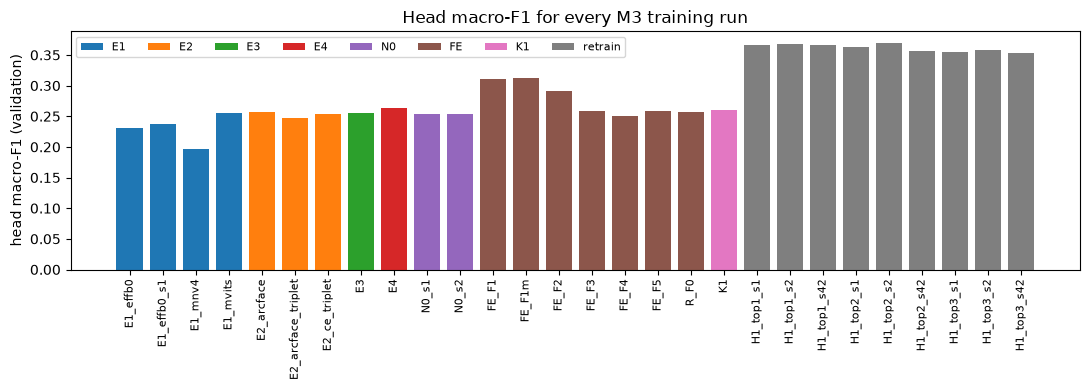

In [9]:
order = ["E1", "E2", "E3", "E4", "N0", "FE", "K1", "retrain"]
plot = runs[runs["stage"].isin(order)].sort_values(["stage", "run"], key=lambda s: s.map(order.index) if s.name == "stage" else s)
fig, ax = plt.subplots(figsize=(11, 4))
colors = plt.cm.tab10(range(len(order)))
for i, name in enumerate(order):
    part = plot[plot["stage"] == name]
    ax.bar(part["run"], part["macro-F1 head"], color=colors[i], label=name)
ax.set_ylabel("head macro-F1 (validation)")
ax.set_title("Head macro-F1 for every M3 training run")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.legend(ncol=8, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 9. Our final model against B1, the published SnakeCLEF 2021 model

Both models scored with notebook 11's scoring function, on all 184 species and on the 62 species B1 knows ("closed set": ours may only answer with those 62). The 2022 slice holds photos uploaded from 2022, which B1 cannot have trained on. This needs the final run's `val_outputs.npz` and the dataset metadata from Kaggle; without them the cell reads the saved table.

In [10]:
import json
import sys

import numpy as np

WORKSPACE = Path("..").resolve().parent   # the folder holding the repo and kaggle/
RUN_DIR = WORKSPACE / "kaggle" / "m3_runs" / "stageC" / "final_candidates" / "top1_s1" / "H1_top1_s1"
METADATA = WORKSPACE / "kaggle" / "clean_build" / "out" / "metadata.csv"
B1_FILE = WORKSPACE / "kaggle" / "m3_runs" / "stageD" / "out_nb11" / "baselines" / "B1" / "final_metrics.json"
B1_TABLE = SUMMARY / "b1_comparison.csv"


def per_class_scores(per_class, classes):
    per_class = {str(k): v for k, v in per_class.items()}  # JSON keys are text, in-memory keys are ints
    rows = [per_class[str(c)] for c in classes if per_class[str(c)]["support"] > 0]
    support, recall = np.array([r["support"] for r in rows]), np.array([r["recall"] for r in rows])
    return {"top-1": (recall * support).sum() / support.sum(), "mean recall": recall.mean(),
            "macro-F1": np.mean([r["f1"] for r in rows])}


if RUN_DIR.exists():
    sys.path.insert(0, str(Path("../src").resolve()))
    from serpentguard.run_outputs import class_tables

    scoring = {}  # notebook 11's scoring cell: the function every baseline, B1 among them, was scored with
    nb11 = json.loads(Path("11_m3_baselines.ipynb").read_text())
    exec(next("".join(c["source"]) for c in nb11["cells"] if c.get("id") == "scoring"), scoring)
    PATH, CLASS_ID, SLICE = scoring["PATH"], scoring["CLASS_ID"], scoring["UPLOAD_2022"]

    out = np.load(RUN_DIR / "val_outputs.npz")
    logits, labels = out["species_logits"].astype(np.float64), out["labels"]
    probs = np.exp(logits - logits.max(axis=1, keepdims=True))
    probs /= probs.sum(axis=1, keepdims=True)
    val = pd.DataFrame({PATH: out["paths"], CLASS_ID: labels, "genus_id": out["genus_id"], "family_id": out["family_id"]})
    taxa = class_tables(pd.read_csv("../data/classes.csv"))
    in_2022 = scoring["upload_2022_slice"](val, pd.read_csv(METADATA, usecols=[PATH, "created_at"], dtype=str))
    no_counts = np.zeros(taxa.n_classes, dtype=int)  # training counts only feed the tier split, not used here
    ours = scoring["baseline_metrics"](val, probs, no_counts, taxa, in_2022, {"run": RUN_DIR.name})
    b1 = json.loads(B1_FILE.read_text())
    shared = sorted(b1["coverage"]["covered_class_ids"])

    own = json.loads((RUN_DIR / "final_metrics.json").read_text())["head"]["macro_f1"]
    assert abs(ours["head"]["macro_f1"] - own) < 1e-9, "the scoring function must reproduce the run's own macro-F1"
    shuffled = val.assign(**{CLASS_ID: np.random.default_rng(0).permutation(labels)})
    control = scoring["baseline_metrics"](shuffled, probs, no_counts, taxa, in_2022, {"run": "shuffled"})["head"]["macro_f1"]
    assert control < 0.02, "with shuffled labels the score must fall to chance"
    for model in (ours, b1):  # per-class figures must rebuild each model's own top-1
        for head in (model["head"], model[SLICE]["head"]):
            assert abs(per_class_scores(head["per_class"], range(taxa.n_classes))["top-1"] - head["top1"]) < 1e-9
    print(f"checks: reproduces the run's macro-F1 {own:.3f}; shuffled labels score {control:.3f}; "
          f"{len(shared)} species shared; {int(in_2022.sum())} photos uploaded from 2022")

    rows = []
    for evaluation, keep, o, b in (("full validation", np.ones(len(labels), bool), ours["head"], b1["head"]),
                                   ("uploaded from 2022", in_2022, ours[SLICE]["head"], b1[SLICE]["head"])):
        for model, head in (("ours", o), ("B1", b)):
            rows.append({"evaluation": evaluation, "species": "all 184", "model": model, "macro-F1": head["macro_f1"],
                         "top-1": head["top1"], "top-3": head["top3"]})
            rows.append({"evaluation": evaluation, "species": "62 B1 knows", "model": model,
                         **per_class_scores(head["per_class"], shared)})
        mask = np.isin(labels, shared) & keep
        pred, truth = np.asarray(shared)[logits[mask][:, shared].argmax(axis=1)], labels[mask]
        rows.append({"evaluation": evaluation, "species": "62 B1 knows", "model": "ours, closed set",
                     "top-1": np.mean(pred == truth),
                     "mean recall": np.mean([np.mean(pred[truth == c] == c) for c in shared if np.any(truth == c)])})
    pd.DataFrame(rows).to_csv(B1_TABLE, index=False)

pd.read_csv(B1_TABLE).set_index(["evaluation", "species", "model"])

checks: reproduces the run's macro-F1 0.367; shuffled labels score 0.006; 62 species shared; 13947 photos uploaded from 2022


macro-F1  top-1  top-3  mean recall
evaluation         species     model                                                
full validation    all 184     ours                 0.367  0.622  0.762          NaN
                   62 B1 knows ours                 0.568  0.682    NaN        0.585
                   all 184     B1                   0.257  0.683  0.771          NaN
                   62 B1 knows B1                   0.653  0.801    NaN        0.755
                               ours, closed set       NaN  0.701    NaN        0.603
uploaded from 2022 all 184     ours                 0.357  0.617  0.756          NaN
                   62 B1 knows ours                 0.560  0.679    NaN        0.577
                   all 184     B1                   0.252  0.674  0.767          NaN
                   62 B1 knows B1                   0.637  0.788    NaN        0.737
                               ours, closed set       NaN  0.697    NaN        0.594